# EDA C: Lịch sử lưu lượng

Các phép kiểm tra dùng chung nằm trong `src/eda/helpers.py`. Notebook chỉ giữ phần phân tích và nhận xét.

In [1]:
from pathlib import Path
import sys
project_root = next((folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / 'data/Metro_Interstate_Traffic_Volume.csv').is_file()))
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import TimeSeriesSplit
from src.eda import helpers as eda_tools
from src.features import CONFIG_A, CONFIG_B, CONFIG_C, HISTORY_FEATURES, WEATHER_GROUPS
SEED = eda_tools.SEED
MIN_GROUP = eda_tools.MIN_GROUP
MIN_HISTORY = eda_tools.MIN_HISTORY

In [2]:
context = eda_tools.load_context(project_root)
train = context['train']

In [3]:
history_complete = train[HISTORY_FEATURES].notna().all(axis=1)
history_cohort = train.loc[history_complete].copy()
display(Markdown(f'**Mục tiêu:** khảo sát quan hệ và độ phủ của lưu lượng quá khứ theo timestamp.  \n**Kết luận chính:** {len(history_cohort):,}/{len(train):,} giờ train đủ ba feature lịch sử theo quy tắc ít nhất {MIN_HISTORY}/24 giờ.  \n**Quyết định:** đề xuất C30 cho phần FE khi quá khứ sẵn có; kiểm tra không dùng y(t).'))

**Mục tiêu:** khảo sát quan hệ và độ phủ của lưu lượng quá khứ theo timestamp.  
**Kết luận chính:** 22,503/28,402 giờ train đủ ba feature lịch sử theo quy tắc ít nhất 18/24 giờ.  
**Quyết định:** đề xuất C30 cho phần FE khi quá khứ sẵn có; kiểm tra không dùng y(t).

## 1. Câu hỏi và giả thuyết

Lưu lượng quá khứ có giúp dự đoán tốt hơn B27 không? `lag_24h` lấy đúng giờ hôm trước, còn `lag_168h` lấy đúng giờ tuần trước.

## 2. Ý tưởng tách đặc trưng

History mang thông tin về trạng thái giao thông gần đây. `mean_24h` chỉ lấy 24 giờ trước t, cần ít nhất 18 giờ có dữ liệu. Giờ vắng giữ thiếu, không điền lưu lượng bằng 0.

## 3. Đặc trưng được tạo

In [4]:
display(eda_tools.feature_spec(context, 'C'))

,feature,formula,dtype,source,missing_rule,n
0,hour,date_time.dt.hour,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
1,day_of_week,date_time.dt.dayofweek (Monday=0),int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
2,month,date_time.dt.month,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
3,is_weekend,day_of_week >= 5,int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
4,is_rush_hour,"hour thuộc (6, 7, 8, 15, 16, 17) và is_weekend=0",int8,date_time,không thiếu sau kiểm tra; chưa biết lễ bị bỏ sót,28402
5,hour_sin,sin(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
6,hour_cos,cos(2*pi*(hour)/24),float64,date_time,không thiếu sau kiểm tra timestamp,28402
7,day_of_week_sin,sin(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
8,day_of_week_cos,cos(2*pi*(day_of_week)/7),float64,date_time,không thiếu sau kiểm tra timestamp,28402
9,month_sin,sin(2*pi*(month-1)/12),float64,date_time,không thiếu sau kiểm tra timestamp,28402


In [5]:
history_series = train.set_index('date_time').traffic_volume
lag_examples = train[['date_time', 'traffic_volume', *HISTORY_FEATURES, 'n_history_24h']].copy()
lag_examples['source_24h'] = lag_examples.date_time - pd.Timedelta(hours=24)
lag_examples['source_168h'] = lag_examples.date_time - pd.Timedelta(hours=168)
lag_examples['n'] = 1
display(lag_examples.head(12))

,date_time,traffic_volume,lag_24h,lag_168h,mean_24h,n_history_24h,source_24h,source_168h,n
0,2012-10-02 09:00:00,5545,NaN,NaN,NaN,0,2012-10-01 09:00:00,2012-09-25 09:00:00,1
1,2012-10-02 10:00:00,4516,NaN,NaN,NaN,1,2012-10-01 10:00:00,2012-09-25 10:00:00,1
2,2012-10-02 11:00:00,4767,NaN,NaN,NaN,2,2012-10-01 11:00:00,2012-09-25 11:00:00,1
3,2012-10-02 12:00:00,5026,NaN,NaN,NaN,3,2012-10-01 12:00:00,2012-09-25 12:00:00,1
4,2012-10-02 13:00:00,4918,NaN,NaN,NaN,4,2012-10-01 13:00:00,2012-09-25 13:00:00,1
5,2012-10-02 14:00:00,5181,NaN,NaN,NaN,5,2012-10-01 14:00:00,2012-09-25 14:00:00,1
6,2012-10-02 15:00:00,5584,NaN,NaN,NaN,6,2012-10-01 15:00:00,2012-09-25 15:00:00,1
7,2012-10-02 16:00:00,6015,NaN,NaN,NaN,7,2012-10-01 16:00:00,2012-09-25 16:00:00,1
8,2012-10-02 17:00:00,5791,NaN,NaN,NaN,8,2012-10-01 17:00:00,2012-09-25 17:00:00,1
9,2012-10-02 18:00:00,4770,NaN,NaN,NaN,9,2012-10-01 18:00:00,2012-09-25 18:00:00,1


## 4. Chất lượng và phân phối

In [6]:
eda_tools.audit_context(context)

,item,observed,expected,matches,n
0,rows,48204,48204,True,48204
1,columns,9,9,True,48204
2,unique_timestamps,40575,40575,True,48204
3,extra_timestamp_rows,7629,7629,True,48204
4,missing_hours,11976,11976,True,48204


,split,start,end,n
0,train,2012-10-02 09:00:00,2017-05-10 04:00:00,28402
1,validation,2017-05-10 05:00:00,2018-01-19 14:00:00,6086
2,test,2018-01-19 15:00:00,2018-09-30 23:00:00,6087


Các số kiểm toán khớp mốc cung cấp; phân tích feature bên dưới dùng **28,402 giờ train**, chưa chấm validation/test. Timestamp không có timezone; chưa phân tích DST (đổi giờ mùa hè). Nhãn lễ lấy theo ngày có ghi trong CSV, chưa tự bổ sung lịch ngoài. Nhãn hiếm đánh dấu khi n < 30; đây là ngưỡng mô tả, không phải kiểm định.

In [7]:
display(eda_tools.quality(train, CONFIG_C))

,feature,missing,missing_pct,minimum,maximum,distinct,n
0,hour,0,0.000000,0.000000,23.000000,24,28402
1,day_of_week,0,0.000000,0.000000,6.000000,7,28402
2,month,0,0.000000,1.000000,12.000000,12,28402
3,is_weekend,0,0.000000,0.000000,1.000000,2,28402
4,is_rush_hour,0,0.000000,0.000000,1.000000,2,28402
5,hour_sin,0,0.000000,-1.000000,1.000000,21,28402
6,hour_cos,0,0.000000,-1.000000,1.000000,22,28402
7,day_of_week_sin,0,0.000000,-0.974928,0.974928,7,28402
8,day_of_week_cos,0,0.000000,-0.900969,1.000000,7,28402
9,month_sin,0,0.000000,-1.000000,1.000000,11,28402


In [8]:
coverage_history = pd.DataFrame([dict(rule='ít nhất 18/24 quan sát', complete_features=int(history_complete.sum()), n=len(train)), dict(rule='đủ 24/24 quan sát', complete_features=int(train[['lag_24h', 'lag_168h', 'mean_24h_strict']].notna().all(axis=1).sum()), n=len(train))])
display(coverage_history)
window_support = train.groupby('n_history_24h').traffic_volume.size().rename('n').reset_index()
window_support['small_group'] = window_support.n.lt(MIN_GROUP)
display(window_support)

,rule,complete_features,n
0,ít nhất 18/24 quan sát,22503,28402
1,đủ 24/24 quan sát,16452,28402


,n_history_24h,n,small_group
0,0,13,True
1,1,21,True
2,2,24,True
3,3,28,True
4,4,30,False
5,5,34,False
6,6,48,False
7,7,54,False
8,8,60,False
9,9,70,False


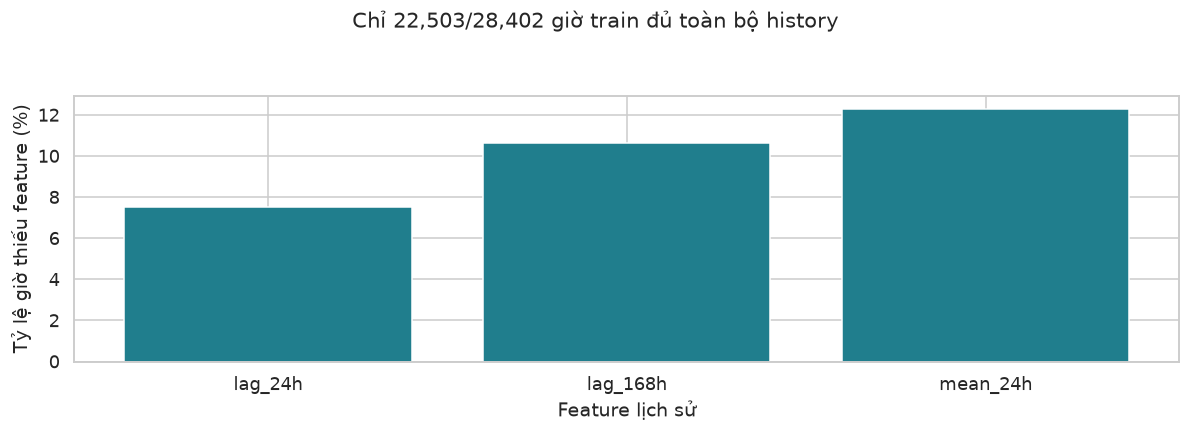

Cột đo tỷ lệ thiếu từng feature, không cộng các cột vì các giờ thiếu có thể trùng nhau. Độ phủ phụ thuộc gaps và thời điểm đầu chuỗi.

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
support = eda_tools.quality(train, HISTORY_FEATURES)
ax.bar(support.feature, support.missing_pct, color='#207E8D')
ax.set(xlabel='Feature lịch sử', ylabel='Tỷ lệ giờ thiếu feature (%)')
eda_tools.figure(context, 'C', 1, 'history_missing', fig, f'Chỉ {len(history_cohort):,}/{len(train):,} giờ train đủ toàn bộ history', 'Cột đo tỷ lệ thiếu từng feature, không cộng các cột vì các giờ thiếu có thể trùng nhau. Độ phủ phụ thuộc gaps và thời điểm đầu chuỗi.')

## 5. Quan hệ với mục tiêu

In [10]:
lag_relations = eda_tools.continuous_relation(train, HISTORY_FEATURES)
display(lag_relations)

,feature,Pearson,Spearman,n
0,lag_24h,0.862253,0.856568,26263
1,lag_168h,0.947225,0.943291,25383
2,mean_24h,0.187157,0.168577,24911


In [11]:
history_acf = eda_tools.acf_pairs(train, 168)
display(history_acf)

,lag_hours,ACF,n
0,0,1.000000,28402
1,1,0.913758,25837
2,2,0.725023,26726
3,3,0.516859,26076
4,4,0.320027,26554
...,...,...,...
164,164,0.298920,25300
165,165,0.490913,25349
166,166,0.692516,25346
167,167,0.871103,25337


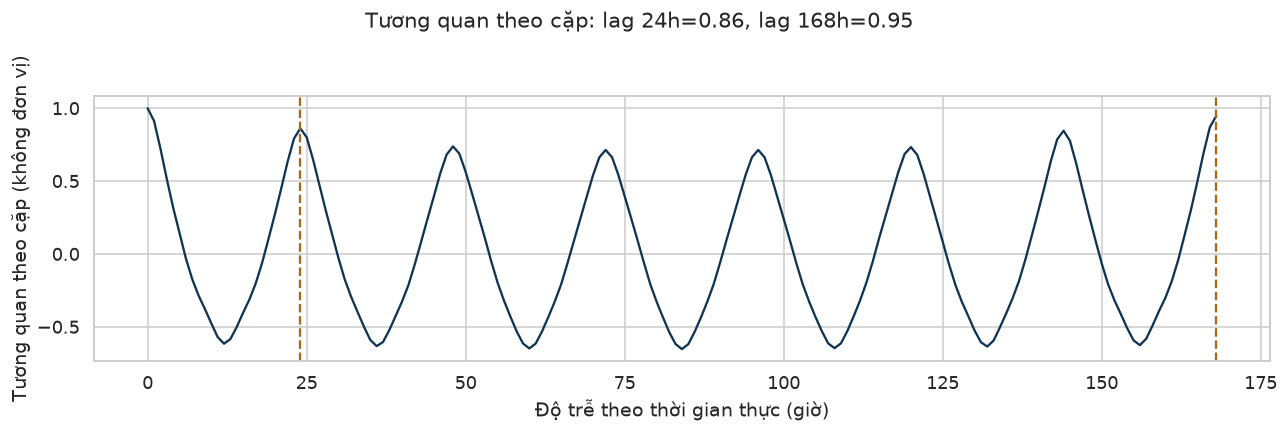

ACF ở đây là Pearson theo các cặp giờ hợp lệ cho mỗi lag, không nối chuỗi qua gaps. n khác nhau theo lag; không gắn dải tin cậy white-noise mặc định.

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(history_acf.lag_hours, history_acf.ACF, color='#103451')
for lag in [24, 168]:
    ax.axvline(lag, color='#A66A1F', linestyle='--')
ax.set(xlabel='Độ trễ theo thời gian thực (giờ)', ylabel='Tương quan theo cặp (không đơn vị)')
corr24 = float(history_acf.loc[history_acf.lag_hours.eq(24), 'ACF'].iloc[0])
corr168 = float(history_acf.loc[history_acf.lag_hours.eq(168), 'ACF'].iloc[0])
eda_tools.figure(context, 'C', 2, 'acf', fig, f'Tương quan theo cặp: lag 24h={corr24:.2f}, lag 168h={corr168:.2f}', 'ACF ở đây là Pearson theo các cặp giờ hợp lệ cho mỗi lag, không nối chuỗi qua gaps. n khác nhau theo lag; không gắn dải tin cậy white-noise mặc định.')

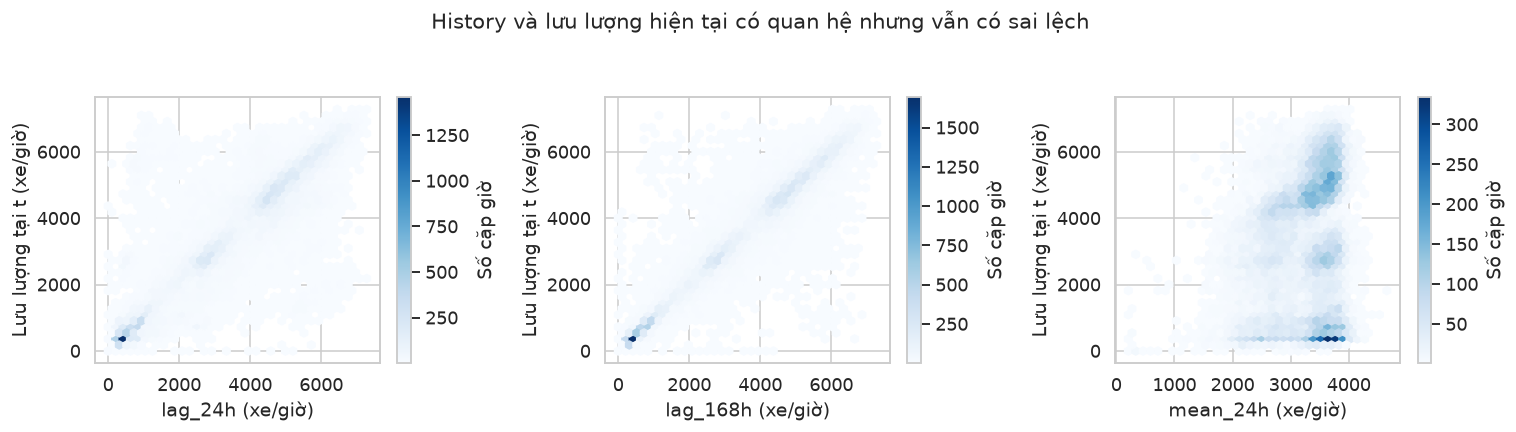

Mỗi ô gom các cặp quá khứ/hiện tại. Đọc cùng Pearson, Spearman và n; tương quan cao chưa cho biết ích lợi ngoài B27.

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(axes, HISTORY_FEATURES):
    pair = train[[f, 'traffic_volume']].dropna()
    image = ax.hexbin(pair[f], pair.traffic_volume, gridsize=35, mincnt=1, cmap='Blues')
    ax.set(xlabel=f'{f} (xe/giờ)', ylabel='Lưu lượng tại t (xe/giờ)')
    fig.colorbar(image, ax=ax, label='Số cặp giờ')
eda_tools.figure(context, 'C', 3, 'lag_target', fig, 'History và lưu lượng hiện tại có quan hệ nhưng vẫn có sai lệch', 'Mỗi ô gom các cặp quá khứ/hiện tại. Đọc cùng Pearson, Spearman và n; tương quan cao chưa cho biết ích lợi ngoài B27.')

In [14]:
history_bins = {f: eda_tools.binned(train, f) for f in HISTORY_FEATURES}
for frame in history_bins.values():
    display(frame)

,bin,mean,n,feature,small_group
0,"(-0.01, 720.00]",597.576642,4384,lag_24h,False
1,"(720.00, 2185.00]",1778.824794,4372,lag_24h,False
2,"(2185.00, 3335.00]",2818.179534,4378,lag_24h,False
3,"(3335.00, 4551.00]",4132.592914,4375,lag_24h,False
4,"(4551.00, 5379.00]",4750.241891,4378,lag_24h,False
5,"(5379.00, 7280.00]",5431.427331,4376,lag_24h,False


,bin,mean,n,feature,small_group
0,"(-0.01, 716.00]",475.696176,4236,lag_168h,False
1,"(716.00, 2161.67]",1431.089941,4225,lag_168h,False
2,"(2161.67, 3318.00]",2860.840700,4231,lag_168h,False
3,"(3318.00, 4540.33]",4060.674704,4230,lag_168h,False
4,"(4540.33, 5365.00]",4844.211198,4233,lag_168h,False
5,"(5365.00, 7280.00]",5752.279801,4228,lag_168h,False


,bin,mean,n,feature,small_group
0,"(206.61, 2692.57]",2410.730010,4152,mean_24h,False
1,"(2692.57, 3119.26]",3136.421002,4152,mean_24h,False
2,"(3119.26, 3407.15]",3603.768545,4152,mean_24h,False
3,"(3407.15, 3593.94]",3492.082872,4151,mean_24h,False
4,"(3593.94, 3745.50]",3569.087187,4152,mean_24h,False
5,"(3745.50, 4654.00]",3346.898362,4152,mean_24h,False


VIF giúp nhận diện feature trùng thông tin tuyến tính; không dùng riêng chỉ số này để bỏ cột.

In [15]:
corr_c, vif_c = eda_tools.correlation_and_vif(train, CONFIG_C)
display(vif_c)

,feature,VIF,note,n
0,hour,2.949974,chưa vượt ngưỡng mô tả 5,22493
1,day_of_week,8.740348,đa cộng tuyến tuyến tính,22493
2,month,2.655880,chưa vượt ngưỡng mô tả 5,22493
3,is_weekend,8.664356,đa cộng tuyến tuyến tính,22493
4,is_rush_hour,2.369807,chưa vượt ngưỡng mô tả 5,22493
5,hour_sin,2.849236,chưa vượt ngưỡng mô tả 5,22493
6,hour_cos,4.998159,chưa vượt ngưỡng mô tả 5,22493
7,day_of_week_sin,2.995963,chưa vượt ngưỡng mô tả 5,22493
8,day_of_week_cos,4.001881,chưa vượt ngưỡng mô tả 5,22493
9,month_sin,2.681964,chưa vượt ngưỡng mô tả 5,22493


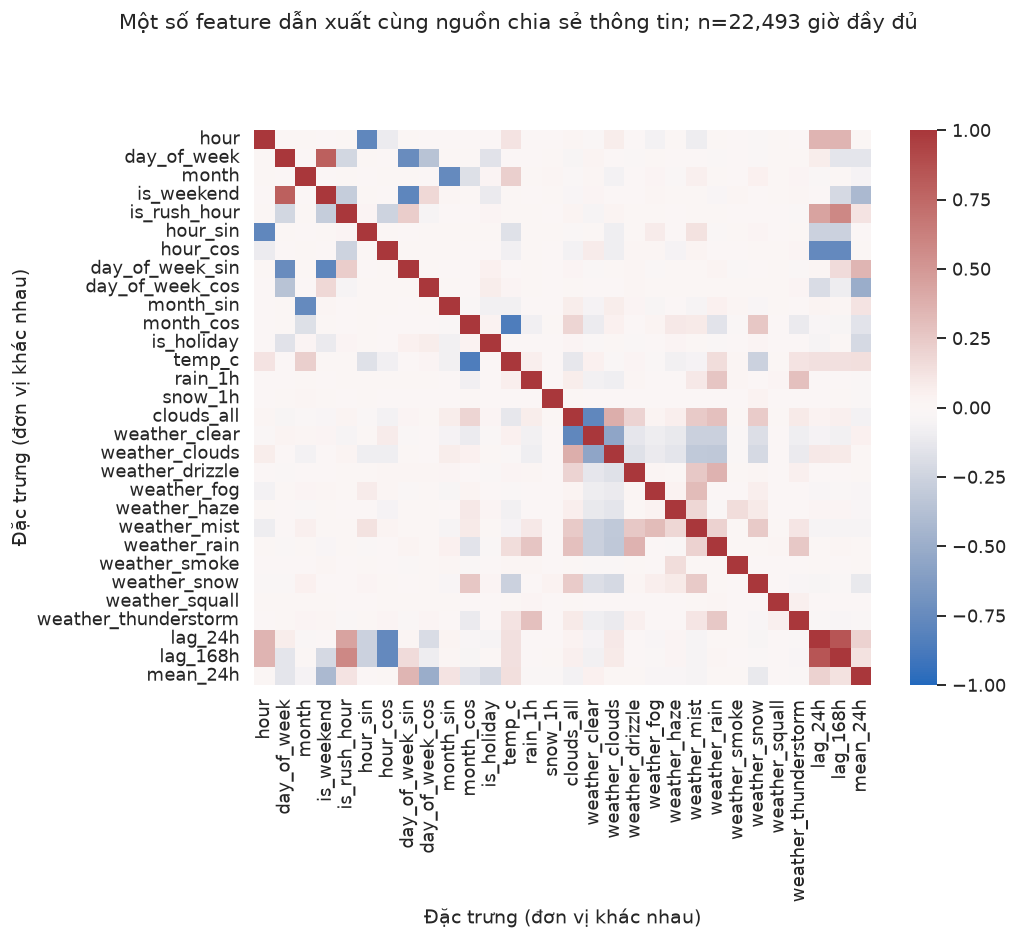

Màu thể hiện Pearson giữa các feature, không dùng để đánh giá liên hệ của mã giờ/thứ/tháng thô với target. Ô trống là hệ số không xác định, thường do biến hằng; không tự bỏ feature chỉ từ hình này.

In [16]:
eda_tools.corr_plot(context, 'C', corr_c, 4, len(train[CONFIG_C].dropna()))

## 6. Rủi ro rò rỉ và độ ổn định

In [17]:
for hours in [24, 168]:
    expected = (train.date_time - pd.Timedelta(hours=hours)).map(history_series)
    pd.testing.assert_series_equal(train[f'lag_{hours}h'], expected, check_names=False)
lookup_checks = []
for hours in [24, 168]:
    wrong = train.traffic_volume.shift(hours)
    correct = train[f'lag_{hours}h']
    differs = ~(wrong.eq(correct) | wrong.isna() & correct.isna())
    lookup_checks.append(dict(lag_hours=hours, rows_differ_from_shift=int(differs.sum()), n=len(train)))
display(pd.DataFrame(lookup_checks))

,lag_hours,rows_differ_from_shift,n
0,24,11128,28402
1,168,20393,28402


In [18]:
check_time = train.loc[history_complete, 'date_time'].iloc[len(history_cohort) // 2]
changed = history_series.copy()
changed.loc[check_time] += 100000
original_mean = history_series.rolling('24h', closed='left', min_periods=MIN_HISTORY).mean().loc[check_time]
altered_mean = changed.rolling('24h', closed='left', min_periods=MIN_HISTORY).mean().loc[check_time]
assert np.isclose(original_mean, altered_mean)
changed.loc[changed.index >= check_time] = 999999
assert np.isclose(changed.rolling('24h', closed='left', min_periods=MIN_HISTORY).mean().loc[check_time], original_mean)
for hours in [24, 168]:
    source_time = check_time - pd.Timedelta(hours=hours)
    assert source_time < check_time
    assert changed.get(source_time, np.nan) == history_series.get(source_time, np.nan)
display(Markdown(f'Kiểm tra can thiệp tại {check_time}: thay y(t) và tương lai không đổi history tại t. Kiểm tra này xác nhận logic timestamp/cửa sổ ở điểm thử, không thay cho giả định nguồn dữ liệu tới kịp lúc triển khai.'))

Kiểm tra can thiệp tại 2015-07-12 05:00:00: thay y(t) và tương lai không đổi history tại t. Kiểm tra này xác nhận logic timestamp/cửa sổ ở điểm thử, không thay cho giả định nguồn dữ liệu tới kịp lúc triển khai.

In [19]:
probe = pd.DataFrame({'date_time': pd.date_range('2020-01-01', periods=200, freq='h'), 'traffic_volume': np.arange(200, dtype=float)})
probe_full = eda_tools.causal_history(probe)
probe_gapped = eda_tools.causal_history(probe.drop(index=10).reset_index(drop=True))
assert pd.isna(probe_gapped.loc[probe_gapped.date_time.eq(pd.Timestamp('2020-01-02 10:00')), 'lag_24h'].iloc[0])
assert probe_gapped.loc[probe_gapped.date_time.eq(pd.Timestamp('2020-01-08 00:00')), 'lag_168h'].iloc[0] == 0
assert probe_full.loc[24, 'mean_24h'] == np.mean(np.arange(24))
assert pd.isna(probe_full.loc[17, 'mean_24h'])
assert probe_full.loc[18, 'n_history_24h'] == 18
assert pd.isna(probe_full.loc[18, 'mean_24h_strict'])
display(Markdown('Các kiểm tra trên dữ liệu giả lập đều qua: lag không vượt khoảng thiếu, mean đúng biên và đúng số giờ tối thiểu. Đây là kiểm tra logic, không phải bằng chứng hiệu năng model.'))

Các kiểm tra trên dữ liệu giả lập đều qua: lag không vượt khoảng thiếu, mean đúng biên và đúng số giờ tối thiểu. Đây là kiểm tra logic, không phải bằng chứng hiệu năng model.

In [20]:
display(eda_tools.stability(train, HISTORY_FEATURES))

,year,feature,mean,missing_pct,n
0,2012,lag_24h,3239.638488,4.374703,2011
1,2012,lag_168h,3283.824907,10.651450,1879
2,2012,mean_24h,3223.494494,1.759391,2066
3,2013,lag_24h,3286.516695,10.076775,6559
4,2013,lag_168h,3276.231850,13.134083,6336
5,2013,mean_24h,3305.245641,13.819578,6286
6,2014,lag_24h,3251.854152,5.554321,4251
7,2014,lag_168h,3194.726355,9.797823,4060
8,2014,mean_24h,3256.439082,5.087758,4272
9,2015,lag_24h,3246.070305,13.303646,3115


History chỉ sẵn có khi lưu lượng quá khứ đã được ghi nhận. Kết quả này áp dụng cho dự đoán tuần tự từng giờ, chưa đại diện dự báo nhiều bước. Timestamp chưa được xử lý DST.

## 7. Quyết định

Lưu lượng hiện tại có liên hệ với lưu lượng trong quá khứ. Dữ liệu thiếu giờ làm giảm số mẫu có đủ lag, nên phải tra theo timestamp và đếm số quan sát trong cửa sổ mean_24h.

Đề xuất C30 khi lịch sử lưu lượng có sẵn. Phần FE sẽ so năm cấu hình trên cùng tập giờ trước khi chốt phương án; EDA chưa kết luận history giúp giảm sai số mô hình.

[Tài liệu API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html): TimeSeriesSplit mở rộng phần train; khi giờ bị thiếu, các fold cùng số hàng chưa chắc có cùng thời lượng lịch.
[pandas rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html) mô tả cửa sổ thời gian và `closed="left"`.
[Định nghĩa VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).